In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [37]:
orders = pd.read_excel(r"C:\Users\abrar\AppData\Local\Packages\5319275A.WhatsAppDesktop_cv1g1gvanyjgm\LocalState\sessions\47C1A275A2C4A7C004B639DC56AFFC4F58ED2ED8\transfers\2026-45\bad2bbd2-7607-4d56-8b75-62a36d4f3269.xlsx", sheet_name="Orders")

customers = pd.read_excel(r"C:\Users\abrar\AppData\Local\Packages\5319275A.WhatsAppDesktop_cv1g1gvanyjgm\LocalState\sessions\47C1A275A2C4A7C004B639DC56AFFC4F58ED2ED8\transfers\2026-45\bad2bbd2-7607-4d56-8b75-62a36d4f3269.xlsx", sheet_name="Customers")

products = pd.read_excel(r"C:\Users\abrar\AppData\Local\Packages\5319275A.WhatsAppDesktop_cv1g1gvanyjgm\LocalState\sessions\47C1A275A2C4A7C004B639DC56AFFC4F58ED2ED8\transfers\2026-45\bad2bbd2-7607-4d56-8b75-62a36d4f3269.xlsx"orders, sheet_name="Products")

In [41]:
orders

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice,DiscountPct,SalesAmount,CostAmount,Profit,PaymentMethod,SalesChannel,OrderStatus
0,O20000,NaT,C1106,P017,2.0,1103,0.05,2095.70,1368.32,727.38,Net Banking,Online,Delivered
1,O20001,2024-11-22,C1016,P001,2.0,9308,0.10,16754.40,12108.74,4645.66,UPI,Marketplace,Processing
2,O20002,2024-08-04,C1043,P019,1.0,3143,0.05,2985.85,1974.72,1011.13,UPI,NaN,Delivered
3,O20003,2024-10-27,C1073,P017,1.0,1103,0.05,1047.85,862.42,185.43,Debit Card,Marketplace,Shipped
4,O20004,2024-05-11,NaN,NaN,5.0,1216,0.00,6080.00,4054.31,2025.69,UPI,Marketplace,Cancelled
...,...,...,...,...,...,...,...,...,...,...,...,...,...
648,O20648,2025-04-11,C1054,P016,2.0,1216,0.10,2188.80,1367.79,821.01,UPI,Store,Delivered
649,O20649,2024-08-31,C1052,P004,1.0,12157,0.15,10333.45,9317.63,1015.82,Credit Card,Store,Delivered
650,O20010,2024-06-15,C1029,P013,3.0,1122,0.15,2861.10,2556.93,304.17,Cash,Online,Shipped
651,O20055,2024-09-15,C1059,P015,3.0,1095,0.05,3120.75,2361.21,759.54,UPI,Store,Delivered


In [42]:
orders.head()

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice,DiscountPct,SalesAmount,CostAmount,Profit,PaymentMethod,SalesChannel,OrderStatus
0,O20000,NaT,C1106,P017,2.0,1103,0.05,2095.70,1368.32,727.38,Net Banking,Online,Delivered
1,O20001,2024-11-22,C1016,P001,2.0,9308,0.10,16754.40,12108.74,4645.66,UPI,Marketplace,Processing
2,O20002,2024-08-04,C1043,P019,1.0,3143,0.05,2985.85,1974.72,1011.13,UPI,NaN,Delivered
3,O20003,2024-10-27,C1073,P017,1.0,1103,0.05,1047.85,862.42,185.43,Debit Card,Marketplace,Shipped
4,O20004,2024-05-11,NaN,NaN,5.0,1216,0.00,6080.00,4054.31,2025.69,UPI,Marketplace,Cancelled


In [43]:
orders.tail()

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice,DiscountPct,SalesAmount,CostAmount,Profit,PaymentMethod,SalesChannel,OrderStatus
648,O20648,2025-04-11,C1054,P016,2.0,1216,0.10,2188.80,1367.79,821.01,UPI,Store,Delivered
649,O20649,2024-08-31,C1052,P004,1.0,12157,0.15,10333.45,9317.63,1015.82,Credit Card,Store,Delivered
650,O20010,2024-06-15,C1029,P013,3.0,1122,0.15,2861.10,2556.93,304.17,Cash,Online,Shipped
651,O20055,2024-09-15,C1059,P015,3.0,1095,0.05,3120.75,2361.21,759.54,UPI,Store,Delivered
652,O20102,2025-06-01,C1030,P015,10.0,1095,0.00,10950.00,6161.29,4788.71,UPI,NaN,Delivered


In [45]:
orders.shape


(653, 13)

In [46]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 653 entries, 0 to 652
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   OrderID        653 non-null    str           
 1   OrderDate      640 non-null    datetime64[us]
 2   CustomerID     637 non-null    str           
 3   ProductID      637 non-null    str           
 4   Quantity       637 non-null    float64       
 5   UnitPrice      653 non-null    int64         
 6   DiscountPct    653 non-null    float64       
 7   SalesAmount    653 non-null    float64       
 8   CostAmount     653 non-null    float64       
 9   Profit         653 non-null    float64       
 10  PaymentMethod  637 non-null    str           
 11  SalesChannel   636 non-null    str           
 12  OrderStatus    653 non-null    str           
dtypes: datetime64[us](1), float64(5), int64(1), str(6)
memory usage: 66.4 KB


In [47]:
orders.describe()


,OrderDate,Quantity,UnitPrice,DiscountPct,SalesAmount,CostAmount,Profit
count,640,637.000000,653.000000,653.000000,653.000000,653.000000,653.000000
mean,2024-10-27 03:09:00,3.042386,7822.958652,0.057351,23408.299847,16493.682374,6914.617473
min,2024-01-01 00:00:00,1.000000,649.000000,0.000000,519.200000,341.270000,-590.150000
25%,2024-05-16 00:00:00,1.000000,1204.000000,0.000000,3309.000000,2367.140000,857.610000
50%,2024-10-18 00:00:00,3.000000,5573.000000,0.050000,10158.000000,7075.870000,2600.310000
75%,2025-04-03 06:00:00,4.000000,12157.000000,0.100000,28749.600000,19962.020000,8577.460000
max,2025-10-01 00:00:00,10.000000,29508.000000,0.200000,295080.000000,236895.990000,116928.650000
std,NaN,2.075560,8024.676137,0.061234,33949.854404,24247.246562,10766.980282


In [48]:
orders.isnull().sum()

OrderID           0
OrderDate        13
CustomerID       16
ProductID        16
Quantity         16
UnitPrice         0
DiscountPct       0
SalesAmount       0
CostAmount        0
Profit            0
PaymentMethod    16
SalesChannel     17
OrderStatus       0
dtype: int64

In [49]:
orders.duplicated().sum()

np.int64(3)

In [50]:
orders = orders.drop_duplicates()
orders

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice,DiscountPct,SalesAmount,CostAmount,Profit,PaymentMethod,SalesChannel,OrderStatus
0,O20000,NaT,C1106,P017,2.0,1103,0.05,2095.70,1368.32,727.38,Net Banking,Online,Delivered
1,O20001,2024-11-22,C1016,P001,2.0,9308,0.10,16754.40,12108.74,4645.66,UPI,Marketplace,Processing
2,O20002,2024-08-04,C1043,P019,1.0,3143,0.05,2985.85,1974.72,1011.13,UPI,NaN,Delivered
3,O20003,2024-10-27,C1073,P017,1.0,1103,0.05,1047.85,862.42,185.43,Debit Card,Marketplace,Shipped
4,O20004,2024-05-11,NaN,NaN,5.0,1216,0.00,6080.00,4054.31,2025.69,UPI,Marketplace,Cancelled
...,...,...,...,...,...,...,...,...,...,...,...,...,...
645,O20645,2024-10-15,C1009,P011,2.0,25266,0.00,50532.00,31651.45,18880.55,Credit Card,Online,Cancelled
646,O20646,2025-07-01,C1006,P017,5.0,1103,0.00,5515.00,3954.08,1560.92,Cash,NaN,Returned
647,O20647,2024-05-27,C1113,P021,6.0,649,0.10,3504.60,2377.19,1127.41,UPI,Online,Delivered
648,O20648,2025-04-11,C1054,P016,2.0,1216,0.10,2188.80,1367.79,821.01,UPI,Store,Delivered


In [51]:
orders['OrderDate'] = pd.to_datetime(
    orders['OrderDate'], errors='coerce'
)
orders

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice,DiscountPct,SalesAmount,CostAmount,Profit,PaymentMethod,SalesChannel,OrderStatus
0,O20000,NaT,C1106,P017,2.0,1103,0.05,2095.70,1368.32,727.38,Net Banking,Online,Delivered
1,O20001,2024-11-22,C1016,P001,2.0,9308,0.10,16754.40,12108.74,4645.66,UPI,Marketplace,Processing
2,O20002,2024-08-04,C1043,P019,1.0,3143,0.05,2985.85,1974.72,1011.13,UPI,NaN,Delivered
3,O20003,2024-10-27,C1073,P017,1.0,1103,0.05,1047.85,862.42,185.43,Debit Card,Marketplace,Shipped
4,O20004,2024-05-11,NaN,NaN,5.0,1216,0.00,6080.00,4054.31,2025.69,UPI,Marketplace,Cancelled
...,...,...,...,...,...,...,...,...,...,...,...,...,...
645,O20645,2024-10-15,C1009,P011,2.0,25266,0.00,50532.00,31651.45,18880.55,Credit Card,Online,Cancelled
646,O20646,2025-07-01,C1006,P017,5.0,1103,0.00,5515.00,3954.08,1560.92,Cash,NaN,Returned
647,O20647,2024-05-27,C1113,P021,6.0,649,0.10,3504.60,2377.19,1127.41,UPI,Online,Delivered
648,O20648,2025-04-11,C1054,P016,2.0,1216,0.10,2188.80,1367.79,821.01,UPI,Store,Delivered


In [52]:
orders['PaymentMethod'] = orders['PaymentMethod'].fillna('Unknown')
orders

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice,DiscountPct,SalesAmount,CostAmount,Profit,PaymentMethod,SalesChannel,OrderStatus
0,O20000,NaT,C1106,P017,2.0,1103,0.05,2095.70,1368.32,727.38,Net Banking,Online,Delivered
1,O20001,2024-11-22,C1016,P001,2.0,9308,0.10,16754.40,12108.74,4645.66,UPI,Marketplace,Processing
2,O20002,2024-08-04,C1043,P019,1.0,3143,0.05,2985.85,1974.72,1011.13,UPI,NaN,Delivered
3,O20003,2024-10-27,C1073,P017,1.0,1103,0.05,1047.85,862.42,185.43,Debit Card,Marketplace,Shipped
4,O20004,2024-05-11,NaN,NaN,5.0,1216,0.00,6080.00,4054.31,2025.69,UPI,Marketplace,Cancelled
...,...,...,...,...,...,...,...,...,...,...,...,...,...
645,O20645,2024-10-15,C1009,P011,2.0,25266,0.00,50532.00,31651.45,18880.55,Credit Card,Online,Cancelled
646,O20646,2025-07-01,C1006,P017,5.0,1103,0.00,5515.00,3954.08,1560.92,Cash,NaN,Returned
647,O20647,2024-05-27,C1113,P021,6.0,649,0.10,3504.60,2377.19,1127.41,UPI,Online,Delivered
648,O20648,2025-04-11,C1054,P016,2.0,1216,0.10,2188.80,1367.79,821.01,UPI,Store,Delivered


In [53]:
orders['SalesChannel'] = orders['SalesChannel'].fillna('Unknown')
orders

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice,DiscountPct,SalesAmount,CostAmount,Profit,PaymentMethod,SalesChannel,OrderStatus
0,O20000,NaT,C1106,P017,2.0,1103,0.05,2095.70,1368.32,727.38,Net Banking,Online,Delivered
1,O20001,2024-11-22,C1016,P001,2.0,9308,0.10,16754.40,12108.74,4645.66,UPI,Marketplace,Processing
2,O20002,2024-08-04,C1043,P019,1.0,3143,0.05,2985.85,1974.72,1011.13,UPI,Unknown,Delivered
3,O20003,2024-10-27,C1073,P017,1.0,1103,0.05,1047.85,862.42,185.43,Debit Card,Marketplace,Shipped
4,O20004,2024-05-11,NaN,NaN,5.0,1216,0.00,6080.00,4054.31,2025.69,UPI,Marketplace,Cancelled
...,...,...,...,...,...,...,...,...,...,...,...,...,...
645,O20645,2024-10-15,C1009,P011,2.0,25266,0.00,50532.00,31651.45,18880.55,Credit Card,Online,Cancelled
646,O20646,2025-07-01,C1006,P017,5.0,1103,0.00,5515.00,3954.08,1560.92,Cash,Unknown,Returned
647,O20647,2024-05-27,C1113,P021,6.0,649,0.10,3504.60,2377.19,1127.41,UPI,Online,Delivered
648,O20648,2025-04-11,C1054,P016,2.0,1216,0.10,2188.80,1367.79,821.01,UPI,Store,Delivered


In [54]:
orders = orders.dropna(
    subset=['OrderDate', 'CustomerID', 'ProductID', 'Quantity']
)
orders

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice,DiscountPct,SalesAmount,CostAmount,Profit,PaymentMethod,SalesChannel,OrderStatus
1,O20001,2024-11-22,C1016,P001,2.0,9308,0.10,16754.40,12108.74,4645.66,UPI,Marketplace,Processing
2,O20002,2024-08-04,C1043,P019,1.0,3143,0.05,2985.85,1974.72,1011.13,UPI,Unknown,Delivered
3,O20003,2024-10-27,C1073,P017,1.0,1103,0.05,1047.85,862.42,185.43,Debit Card,Marketplace,Shipped
5,O20005,2024-03-10,C1046,P010,3.0,7986,0.20,19166.40,16452.96,2713.44,Credit Card,Online,Delivered
6,O20006,2024-09-08,C1006,P009,1.0,14991,0.00,14991.00,9692.11,5298.89,Net Banking,Store,Delivered
...,...,...,...,...,...,...,...,...,...,...,...,...,...
645,O20645,2024-10-15,C1009,P011,2.0,25266,0.00,50532.00,31651.45,18880.55,Credit Card,Online,Cancelled
646,O20646,2025-07-01,C1006,P017,5.0,1103,0.00,5515.00,3954.08,1560.92,Cash,Unknown,Returned
647,O20647,2024-05-27,C1113,P021,6.0,649,0.10,3504.60,2377.19,1127.41,UPI,Online,Delivered
648,O20648,2025-04-11,C1054,P016,2.0,1216,0.10,2188.80,1367.79,821.01,UPI,Store,Delivered


In [55]:
sales = orders.merge(
    products,
    on='ProductID',
    how='left'
)
sales

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice_x,DiscountPct,SalesAmount,CostAmount,Profit,PaymentMethod,SalesChannel,OrderStatus,ProductName,Category,UnitPrice_y,Supplier
0,O20001,2024-11-22,C1016,P001,2.0,9308,0.10,16754.40,12108.74,4645.66,UPI,Marketplace,Processing,Wireless Mouse,Electronics,9308.0,Northstar Supply
1,O20002,2024-08-04,C1043,P019,1.0,3143,0.05,2985.85,1974.72,1011.13,UPI,Unknown,Delivered,Phone Stand,Accessories,3143.0,Metro Wholesale
2,O20003,2024-10-27,C1073,P017,1.0,1103,0.05,1047.85,862.42,185.43,Debit Card,Marketplace,Shipped,Laptop Bag,Accessories,1103.0,Evergreen Distributors
3,O20005,2024-03-10,C1046,P010,3.0,7986,0.20,19166.40,16452.96,2713.44,Credit Card,Online,Delivered,Side Table,Furniture,7986.0,Northstar Supply
4,O20006,2024-09-08,C1006,P009,1.0,14991,0.00,14991.00,9692.11,5298.89,Net Banking,Store,Delivered,Bookshelf,Furniture,14991.0,Northstar Supply
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
647,O20646,2025-07-01,C1006,P017,5.0,1103,0.00,5515.00,3954.08,1560.92,Cash,Unknown,Returned,Laptop Bag,Accessories,1103.0,Evergreen Distributors
648,O20647,2024-05-27,C1113,P021,6.0,649,0.10,3504.60,2377.19,1127.41,UPI,Online,Delivered,Backpack,Accessories,649.0,Northstar Supply
649,O20648,2025-04-11,C1054,P016,2.0,1216,0.10,2188.80,1367.79,821.01,UPI,Store,Delivered,Folders,Office Supplies,1216.0,Metro Wholesale
650,O20649,2024-08-31,C1052,P004,1.0,12157,0.15,10333.45,9317.63,1015.82,Credit Card,Store,Delivered,Monitor,Electronics,12157.0,Evergreen Distributors


In [56]:
sales = sales.merge(
    customers,
    on='CustomerID',
    how='left'
)
sales

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice_x,DiscountPct,SalesAmount,CostAmount,Profit,...,ProductName,Category,UnitPrice_y,Supplier,CustomerName,City,State,Segment,SignupDate,Email
0,O20001,2024-11-22,C1016,P001,2.0,9308,0.10,16754.40,12108.74,4645.66,...,Wireless Mouse,Electronics,9308.0,Northstar Supply,Tara Menon,Kozhikode,Kerala,Corporate,2025-03-26,customer17@example.com
1,O20002,2024-08-04,C1043,P019,1.0,3143,0.05,2985.85,1974.72,1011.13,...,Phone Stand,Accessories,3143.0,Metro Wholesale,Ananya Sharma,Kochi,Kerala,Consumer,2024-03-17,customer44@example.com
2,O20003,2024-10-27,C1073,P017,1.0,1103,0.05,1047.85,862.42,185.43,...,Laptop Bag,Accessories,1103.0,Evergreen Distributors,Aarav Joseph,Coimbatore,Tamil Nadu,Corporate,2024-04-25,customer74@example.com
3,O20005,2024-03-10,C1046,P010,3.0,7986,0.20,19166.40,16452.96,2713.44,...,Side Table,Furniture,7986.0,Northstar Supply,Diya Joseph,Kozhikode,Kerala,Consumer,2025-09-23,customer47@example.com
4,O20006,2024-09-08,C1006,P009,1.0,14991,0.00,14991.00,9692.11,5298.89,...,Bookshelf,Furniture,14991.0,Northstar Supply,Neha Pillai,Thrissur,Kerala,Consumer,2024-11-30,customer7@example.com
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
654,O20646,2025-07-01,C1006,P017,5.0,1103,0.00,5515.00,3954.08,1560.92,...,Laptop Bag,Accessories,1103.0,Evergreen Distributors,Arjun Joseph,Kozhikode,Kerala,Corporate,2024-05-07,customer20@example.com
655,O20647,2024-05-27,C1113,P021,6.0,649,0.10,3504.60,2377.19,1127.41,...,Backpack,Accessories,649.0,Northstar Supply,Ananya Thomas,Thrissur,Kerala,Corporate,2024-11-05,customer114@example.com
656,O20648,2025-04-11,C1054,P016,2.0,1216,0.10,2188.80,1367.79,821.01,...,Folders,Office Supplies,1216.0,Metro Wholesale,Rohan Pillai,Bengaluru,Karnataka,Consumer,2023-05-27,customer55@example.com
657,O20649,2024-08-31,C1052,P004,1.0,12157,0.15,10333.45,9317.63,1015.82,...,Monitor,Electronics,12157.0,Evergreen Distributors,Aarav Reddy,Mysuru,Karnataka,Consumer,2023-11-22,NaN


In [57]:
sales.head()

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice_x,DiscountPct,SalesAmount,CostAmount,Profit,...,ProductName,Category,UnitPrice_y,Supplier,CustomerName,City,State,Segment,SignupDate,Email
0,O20001,2024-11-22,C1016,P001,2.0,9308,0.10,16754.40,12108.74,4645.66,...,Wireless Mouse,Electronics,9308.0,Northstar Supply,Tara Menon,Kozhikode,Kerala,Corporate,2025-03-26,customer17@example.com
1,O20002,2024-08-04,C1043,P019,1.0,3143,0.05,2985.85,1974.72,1011.13,...,Phone Stand,Accessories,3143.0,Metro Wholesale,Ananya Sharma,Kochi,Kerala,Consumer,2024-03-17,customer44@example.com
2,O20003,2024-10-27,C1073,P017,1.0,1103,0.05,1047.85,862.42,185.43,...,Laptop Bag,Accessories,1103.0,Evergreen Distributors,Aarav Joseph,Coimbatore,Tamil Nadu,Corporate,2024-04-25,customer74@example.com
3,O20005,2024-03-10,C1046,P010,3.0,7986,0.20,19166.40,16452.96,2713.44,...,Side Table,Furniture,7986.0,Northstar Supply,Diya Joseph,Kozhikode,Kerala,Consumer,2025-09-23,customer47@example.com
4,O20006,2024-09-08,C1006,P009,1.0,14991,0.00,14991.00,9692.11,5298.89,...,Bookshelf,Furniture,14991.0,Northstar Supply,Neha Pillai,Thrissur,Kerala,Consumer,2024-11-30,customer7@example.com


In [58]:
sales['YearMonth'] = sales['OrderDate'].dt.to_period('M')
sales

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice_x,DiscountPct,SalesAmount,CostAmount,Profit,...,Category,UnitPrice_y,Supplier,CustomerName,City,State,Segment,SignupDate,Email,YearMonth
0,O20001,2024-11-22,C1016,P001,2.0,9308,0.10,16754.40,12108.74,4645.66,...,Electronics,9308.0,Northstar Supply,Tara Menon,Kozhikode,Kerala,Corporate,2025-03-26,customer17@example.com,2024-11
1,O20002,2024-08-04,C1043,P019,1.0,3143,0.05,2985.85,1974.72,1011.13,...,Accessories,3143.0,Metro Wholesale,Ananya Sharma,Kochi,Kerala,Consumer,2024-03-17,customer44@example.com,2024-08
2,O20003,2024-10-27,C1073,P017,1.0,1103,0.05,1047.85,862.42,185.43,...,Accessories,1103.0,Evergreen Distributors,Aarav Joseph,Coimbatore,Tamil Nadu,Corporate,2024-04-25,customer74@example.com,2024-10
3,O20005,2024-03-10,C1046,P010,3.0,7986,0.20,19166.40,16452.96,2713.44,...,Furniture,7986.0,Northstar Supply,Diya Joseph,Kozhikode,Kerala,Consumer,2025-09-23,customer47@example.com,2024-03
4,O20006,2024-09-08,C1006,P009,1.0,14991,0.00,14991.00,9692.11,5298.89,...,Furniture,14991.0,Northstar Supply,Neha Pillai,Thrissur,Kerala,Consumer,2024-11-30,customer7@example.com,2024-09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
654,O20646,2025-07-01,C1006,P017,5.0,1103,0.00,5515.00,3954.08,1560.92,...,Accessories,1103.0,Evergreen Distributors,Arjun Joseph,Kozhikode,Kerala,Corporate,2024-05-07,customer20@example.com,2025-07
655,O20647,2024-05-27,C1113,P021,6.0,649,0.10,3504.60,2377.19,1127.41,...,Accessories,649.0,Northstar Supply,Ananya Thomas,Thrissur,Kerala,Corporate,2024-11-05,customer114@example.com,2024-05
656,O20648,2025-04-11,C1054,P016,2.0,1216,0.10,2188.80,1367.79,821.01,...,Office Supplies,1216.0,Metro Wholesale,Rohan Pillai,Bengaluru,Karnataka,Consumer,2023-05-27,customer55@example.com,2025-04
657,O20649,2024-08-31,C1052,P004,1.0,12157,0.15,10333.45,9317.63,1015.82,...,Electronics,12157.0,Evergreen Distributors,Aarav Reddy,Mysuru,Karnataka,Consumer,2023-11-22,NaN,2024-08


In [59]:
monthly_sales = sales.groupby('YearMonth')['SalesAmount'].sum()
monthly_sales

YearMonth
2024-01    1098634.80
2024-02    1086969.05
2024-03     660501.55
2024-04     882437.55
2024-05    1099834.15
2024-06     694657.85
2024-07     573254.50
2024-08     873064.40
2024-09     731179.65
2024-10     646450.70
2024-11     953612.35
2024-12     734003.65
2025-01     703277.60
2025-02     455572.30
2025-03    1167690.20
2025-04     569361.55
2025-05     937866.10
2025-06     542061.90
2025-07     404894.35
2025-08     468399.80
2025-09     717110.40
2025-10      41886.00
Freq: M, Name: SalesAmount, dtype: float64

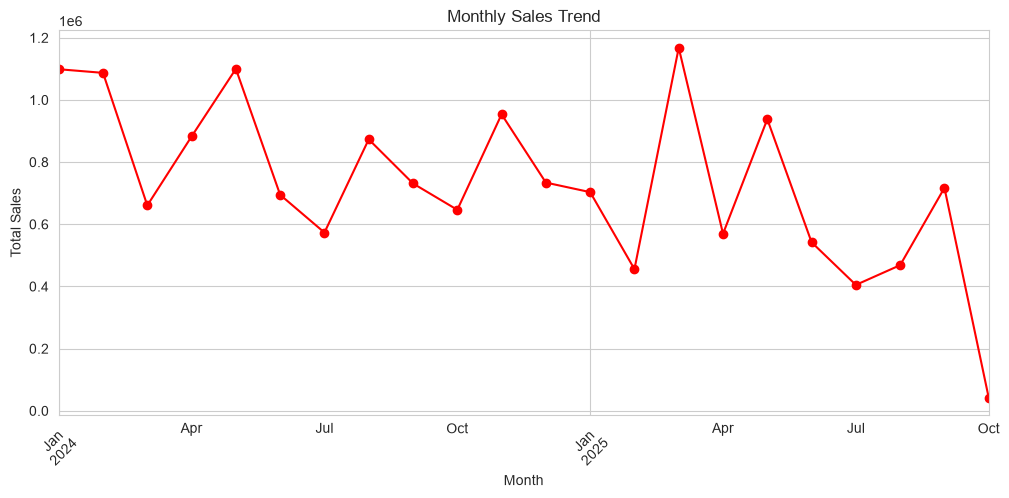

In [63]:
monthly_sales.plot(kind='line', marker='o',color='red', figsize=(12,5))

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

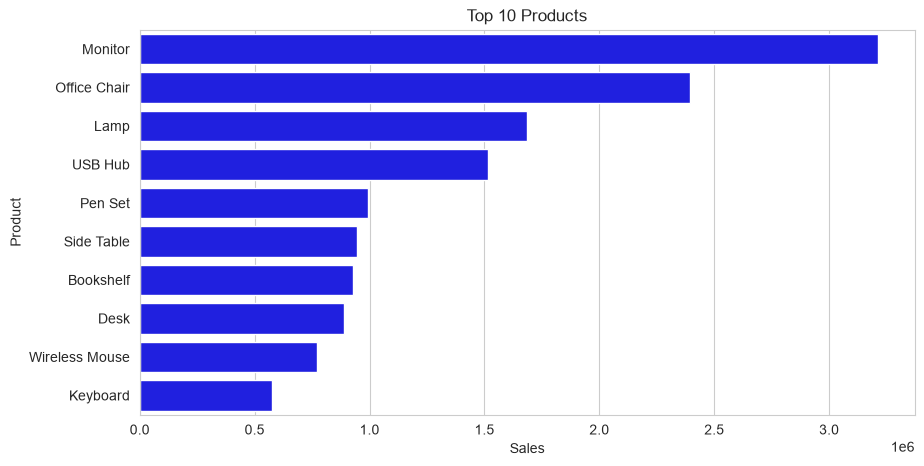

In [62]:
top_products = sales.groupby('ProductName')['SalesAmount'].sum().sort_values(ascending=False).head(10)

sns.barplot(x=top_products.values,color='blue', y=top_products.index)

plt.title('Top 10 Products')
plt.xlabel('Sales')
plt.ylabel('Product')
plt.show()

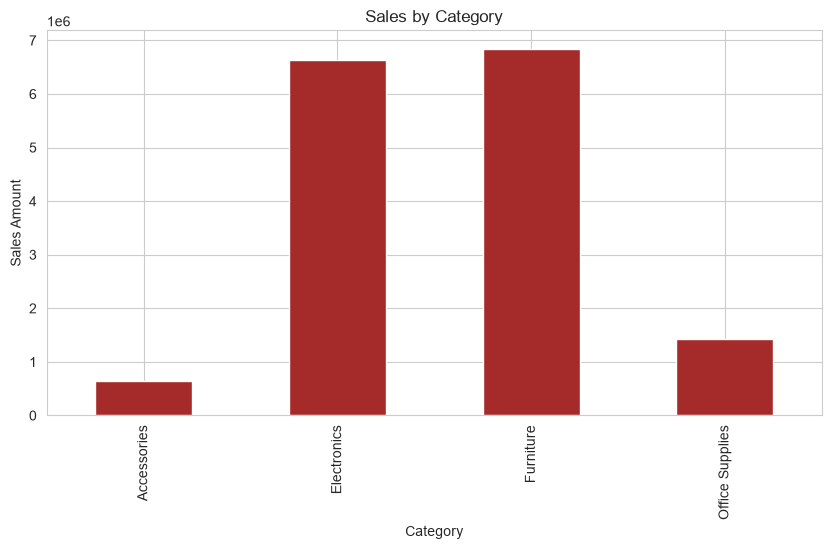

In [64]:
category_sales = sales.groupby('Category')['SalesAmount'].sum()

category_sales.plot(kind='bar',color='brown', figsize=(10,5))

plt.title('Sales by Category')
plt.xlabel('Category')
plt.ylabel('Sales Amount')
plt.show()

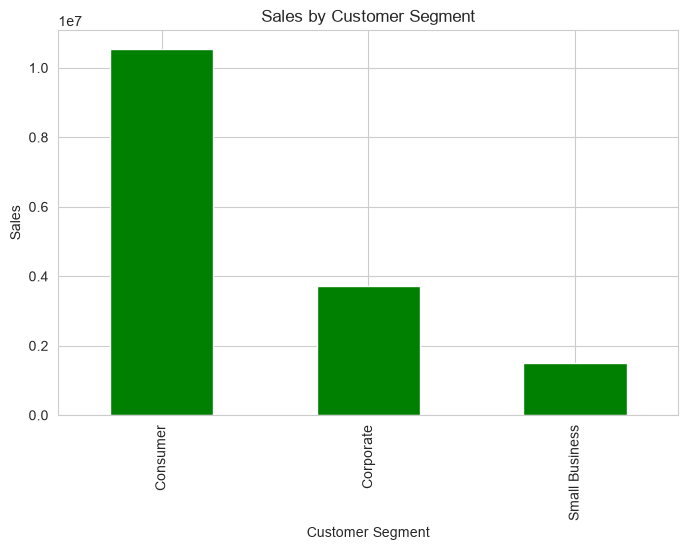

In [65]:
customer_sales = sales.groupby('Segment')['SalesAmount'].sum()

customer_sales.plot(kind='bar',color='green', figsize=(8,5))

plt.title('Sales by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Sales')
plt.show()

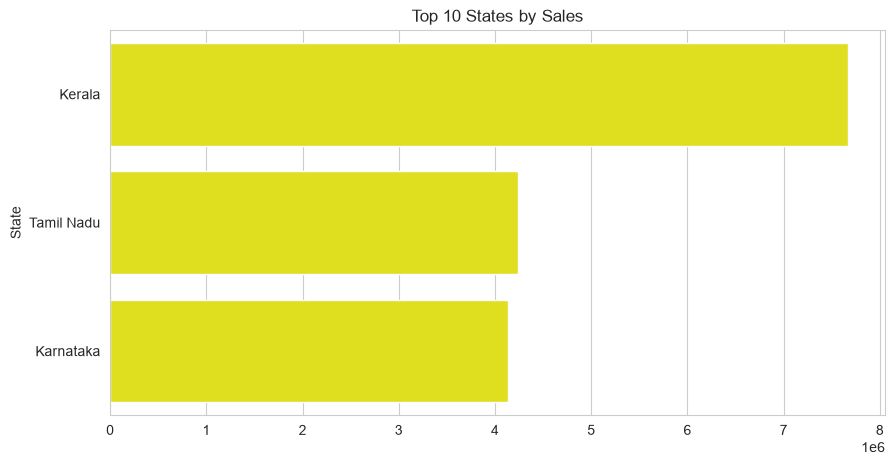

In [66]:
state_sales = sales.groupby('State')['SalesAmount'].sum().sort_values(ascending=False).head(10)

sns.barplot(x=state_sales.values, y=state_sales.index,color='yellow')

plt.title('Top 10 States by Sales')
plt.show()

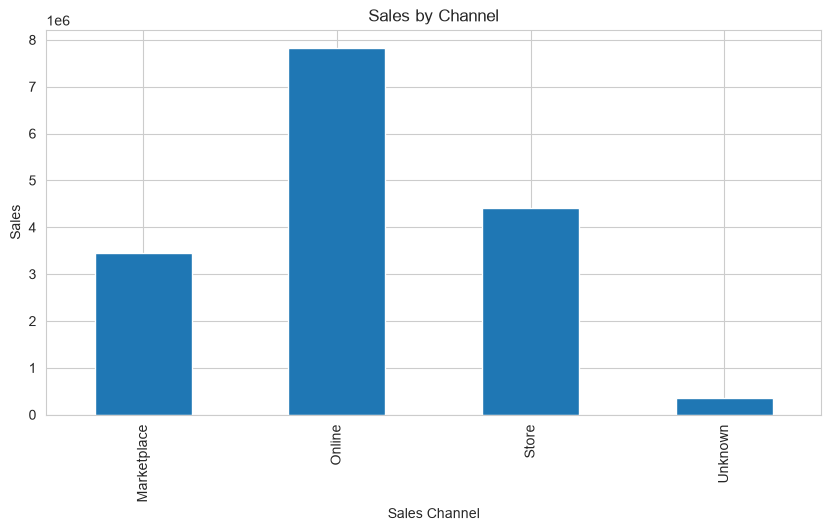

In [67]:
channel_sales = sales.groupby('SalesChannel')['SalesAmount'].sum()

channel_sales.plot(kind='bar')

plt.title('Sales by Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Sales')
plt.show()

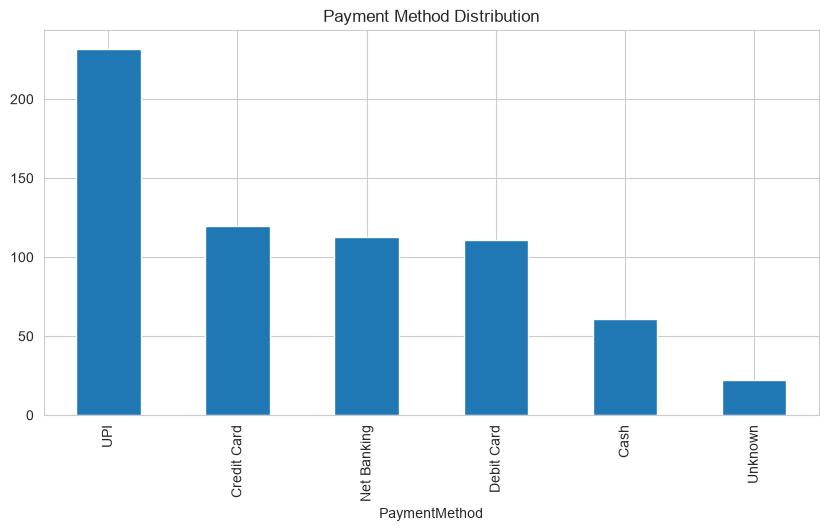

In [68]:
payment = sales['PaymentMethod'].value_counts()

payment.plot(kind='bar')

plt.title('Payment Method Distribution')
plt.show()

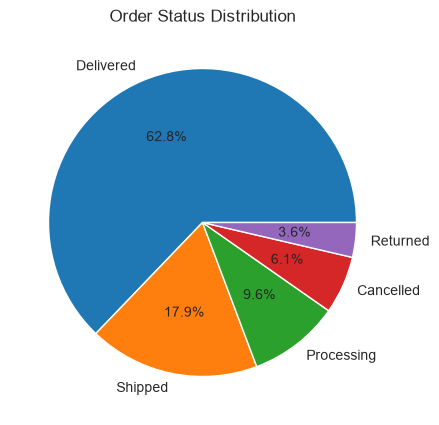

In [69]:
status = sales['OrderStatus'].value_counts()

plt.pie(
    status.values,
    labels=status.index,
    autopct='%1.1f%%'
)

plt.title('Order Status Distribution')
plt.show()

In [70]:
sales['ProfitMargin'] = (
    sales['Profit'] / sales['SalesAmount']
) * 100
sales

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice_x,DiscountPct,SalesAmount,CostAmount,Profit,...,UnitPrice_y,Supplier,CustomerName,City,State,Segment,SignupDate,Email,YearMonth,ProfitMargin
0,O20001,2024-11-22,C1016,P001,2.0,9308,0.10,16754.40,12108.74,4645.66,...,9308.0,Northstar Supply,Tara Menon,Kozhikode,Kerala,Corporate,2025-03-26,customer17@example.com,2024-11,27.728000
1,O20002,2024-08-04,C1043,P019,1.0,3143,0.05,2985.85,1974.72,1011.13,...,3143.0,Metro Wholesale,Ananya Sharma,Kochi,Kerala,Consumer,2024-03-17,customer44@example.com,2024-08,33.864059
2,O20003,2024-10-27,C1073,P017,1.0,1103,0.05,1047.85,862.42,185.43,...,1103.0,Evergreen Distributors,Aarav Joseph,Coimbatore,Tamil Nadu,Corporate,2024-04-25,customer74@example.com,2024-10,17.696235
3,O20005,2024-03-10,C1046,P010,3.0,7986,0.20,19166.40,16452.96,2713.44,...,7986.0,Northstar Supply,Diya Joseph,Kozhikode,Kerala,Consumer,2025-09-23,customer47@example.com,2024-03,14.157275
4,O20006,2024-09-08,C1006,P009,1.0,14991,0.00,14991.00,9692.11,5298.89,...,14991.0,Northstar Supply,Neha Pillai,Thrissur,Kerala,Consumer,2024-11-30,customer7@example.com,2024-09,35.347142
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
654,O20646,2025-07-01,C1006,P017,5.0,1103,0.00,5515.00,3954.08,1560.92,...,1103.0,Evergreen Distributors,Arjun Joseph,Kozhikode,Kerala,Corporate,2024-05-07,customer20@example.com,2025-07,28.303173
655,O20647,2024-05-27,C1113,P021,6.0,649,0.10,3504.60,2377.19,1127.41,...,649.0,Northstar Supply,Ananya Thomas,Thrissur,Kerala,Corporate,2024-11-05,customer114@example.com,2024-05,32.169434
656,O20648,2025-04-11,C1054,P016,2.0,1216,0.10,2188.80,1367.79,821.01,...,1216.0,Metro Wholesale,Rohan Pillai,Bengaluru,Karnataka,Consumer,2023-05-27,customer55@example.com,2025-04,37.509594
657,O20649,2024-08-31,C1052,P004,1.0,12157,0.15,10333.45,9317.63,1015.82,...,12157.0,Evergreen Distributors,Aarav Reddy,Mysuru,Karnataka,Consumer,2023-11-22,NaN,2024-08,9.830405


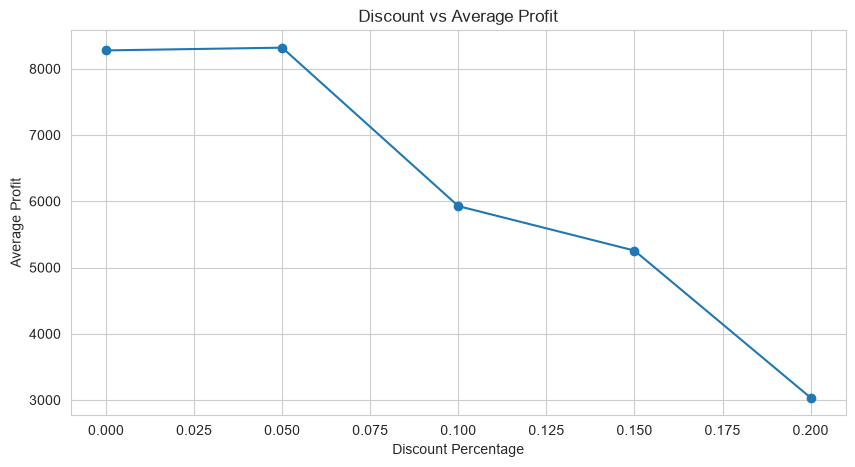

In [71]:
discount_analysis = sales.groupby('DiscountPct')['Profit'].mean()

discount_analysis.plot(kind='line', marker='o')

plt.title('Discount vs Average Profit')
plt.xlabel('Discount Percentage')
plt.ylabel('Average Profit')
plt.show()

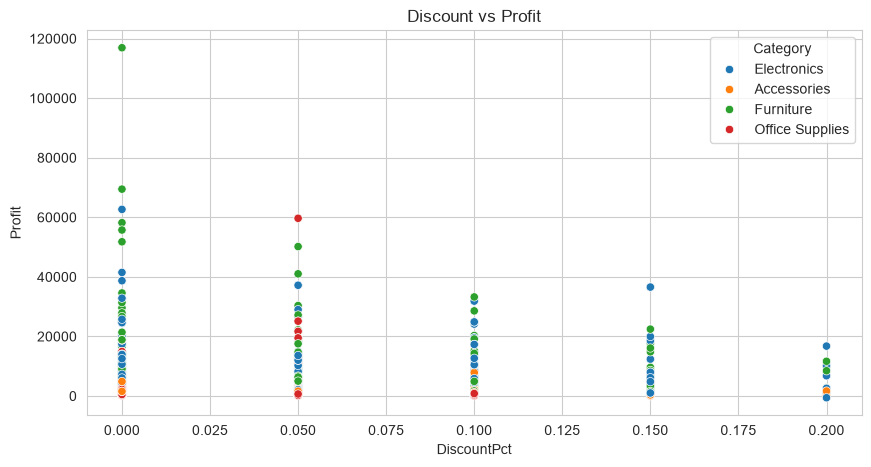

In [72]:
sns.scatterplot(
    data=sales,
    x='DiscountPct',
    y='Profit',
    hue='Category'
)

plt.title('Discount vs Profit')
plt.show()

In [73]:
print("Total Sales:", sales['SalesAmount'].sum())

Total Sales: 16042720.4


In [74]:
print("Total Profit:", sales['Profit'].sum())

Total Profit: 4745029.1899999995


In [75]:
print("Total Orders:", sales['OrderID'].nunique())

Total Orders: 592


In [76]:
print("Total Customers:", sales['CustomerID'].nunique())

Total Customers: 119


In [77]:
print("Total Quantity Sold:", sales['Quantity'].sum())

Total Quantity Sold: 2008.0
